In [15]:
from matplotlib import pyplot as plt

In [1]:
# oadev_core.py
# Minimal, plotting-free utilities for Overlapping Allan Deviation (OADEV)
# Works on uniformly-sampled data.

from __future__ import annotations
import numpy as np
from typing import Iterable, Tuple, Dict, Optional

# -----------------------------
# 0) Preprocessing helpers
# -----------------------------

def to_fractional_power(P: np.ndarray, use_mean: bool = True) -> np.ndarray:
    """
    Convert power vs time to unitless fractional fluctuations y[n].
    If you already have fractional data, skip this.
    y[n] = (P - mean(P)) / mean(P)  (if use_mean=True)

    NaNs/Infs are not handled here—use `nan_guard` first if needed.
    """
    P = np.asarray(P, dtype=float)
    if use_mean:
        Pbar = np.nanmean(P)
        if not np.isfinite(Pbar) or Pbar == 0:
            raise ValueError("Mean power is non-finite or zero.")
        return (P - Pbar) / Pbar
    else:
        Pbar = np.nanmean(P)
        if not np.isfinite(Pbar) or Pbar == 0:
            raise ValueError("Mean power is non-finite or zero.")
        return P / Pbar  # same info, different scaling

def nan_guard(x: np.ndarray) -> np.ndarray:
    """
    Replace NaNs/Infs by linear interpolation across valid points.
    Extrapolates the edges with nearest valid values.
    """
    x = np.asarray(x, dtype=float)
    n = len(x)
    mask = ~np.isfinite(x)
    if not mask.any():
        return x
    idx = np.arange(n)
    y = x.copy()
    y[mask] = np.interp(idx[mask], idx[~mask], x[~mask])
    # Fill ends if interop couldn't (all-NaN edge cases already handled by interp)
    if not np.isfinite(y[0]):
        first = np.flatnonzero(np.isfinite(y))[0]
        y[:first] = y[first]
    if not np.isfinite(y[-1]):
        last = np.flatnonzero(np.isfinite(y))[-1]
        y[last+1:] = y[last]
    return y

# -----------------------------
# 1) Sliding means (step 1–2)
# -----------------------------

def running_mean(y: np.ndarray, m: int) -> np.ndarray:
    """
    Length-(N-m+1) sliding mean via cumulative sums.
    """
    if m < 1:
        raise ValueError("m must be >= 1")
    y = np.asarray(y, dtype=float)
    if len(y) < m:
        return np.array([], dtype=float)
    c = np.concatenate(([0.0], np.cumsum(y)))
    return (c[m:] - c[:-m]) / m

def running_mean_times(N: int, fs: float, m: int) -> np.ndarray:
    """
    Center time for each running mean sample, assuming sample period T0 = 1/fs.
    Returns array of length N-m+1 with times in seconds.
    """
    if m < 1:
        raise ValueError("m must be >= 1")
    if N < m:
        return np.array([], dtype=float)
    T0 = 1.0 / fs
    return (np.arange(N - m + 1) + m / 2.0) * T0

# -----------------------------
# 2) Differences of adjacent m-length means (step 3–4)
# -----------------------------

def adjacent_diff_of_means(ybar: np.ndarray, m: int) -> np.ndarray:
    """
    d[k] = ybar[k+m] - ybar[k], k = 0..len(ybar)-m-1
    Requires len(ybar) >= 2m.
    """
    if m < 1:
        raise ValueError("m must be >= 1")
    L = len(ybar)
    if L < 2*m:
        return np.array([], dtype=float)
    return ybar[m:] - ybar[:-m]

def adjacent_diff_times(N: int, fs: float, m: int) -> np.ndarray:
    """
    Center times for d[k] values.
    Each d[k] compares means centered m/2 before and m/2 after the midpoint between windows,
    so the center is at (k + 1.5*m) samples.
    Returns array of length N - 2m + 1; empty if insufficient length.
    """
    if m < 1:
        raise ValueError("m must be >= 1")
    if N < 2*m:
        return np.array([], dtype=float)
    T0 = 1.0 / fs
    return (np.arange(N - 2*m + 1) + 1.5*m) * T0

# -----------------------------
# 3) Overlapping Allan variance/deviation (step 5)
# -----------------------------

def oavar_from_d(d: np.ndarray) -> Tuple[float, float]:
    """
    Allan variance (overlapping) and deviation from the d[k] sequence:
      sigma^2 = 0.5 * mean(d^2)
      sigma   = sqrt(sigma^2)
    Returns (sigma2, sigma). Returns (nan, nan) if d is empty.
    """
    d = np.asarray(d, dtype=float)
    if d.size == 0:
        return np.nan, np.nan
    sigma2 = 0.5 * float(np.mean(d**2))
    sigma = float(np.sqrt(sigma2))
    return sigma2, sigma

# -----------------------------
# 4) Convenience wrappers
# -----------------------------

def oadev_single_tau(
    y: np.ndarray,
    fs: float,
    m: int
) -> Dict[str, Optional[np.ndarray]]:
    """
    Compute all intermediate arrays for OADEV at tau = m/fs.
    Returns a dict with:
      - 'tau': float
      - 'ybar': np.ndarray (length N-m+1)
      - 't_ybar': np.ndarray (times for ybar)
      - 'd': np.ndarray (length N-2m+1)
      - 't_d': np.ndarray (times for d)
      - 'sigma2': float
      - 'sigma': float
    Arrays may be empty if N < m or N < 2m.
    """
    y = np.asarray(y, dtype=float)
    N = len(y)
    T0 = 1.0 / fs
    tau = m * T0

    ybar = running_mean(y, m)
    t_ybar = running_mean_times(N, fs, m)

    d = adjacent_diff_of_means(ybar, m)
    t_d = adjacent_diff_times(N, fs, m)

    sigma2, sigma = oavar_from_d(d)
    return {
        "tau": tau,
        "ybar": ybar,
        "t_ybar": t_ybar,
        "d": d,
        "t_d": t_d,
        "sigma2": sigma2,
        "sigma": sigma,
    }

def oadev_multi_tau(
    y: np.ndarray,
    fs: float,
    m_values: Iterable[int]
) -> Tuple[np.ndarray, np.ndarray]:
    """
    OADEV for multiple integer m values.
    Returns:
      taus  : array of τ = m/fs (float)
      sigmas: array of OADEV values σ_y(τ)
    """
    y = np.asarray(y, dtype=float)
    m_values = np.unique(np.asarray(list(m_values), dtype=int))
    taus = m_values / float(fs)
    sigmas = np.empty_like(taus, dtype=float)
    for i, m in enumerate(m_values):
        res = oadev_single_tau(y, fs, int(m))
        sigmas[i] = res["sigma"]
    return taus, sigmas

# -----------------------------
# 5) Example orchestration (no plotting)
# -----------------------------
if __name__ == "__main__":
    # Example: create synthetic fractional series and compute OADEV pieces.
    rng = np.random.default_rng(7)
    fs = 200.0
    T = 20.0
    N = int(fs * T)
    t = np.arange(N) / fs

    # Example data (replace with yours):
    # If you have power P(t), do y = to_fractional_power(P)
    y = 2e-3 * rng.standard_normal(N) + 3e-4 * np.cumsum(rng.standard_normal(N)) / np.sqrt(N)

    # Choose one tau for step-by-step inspection
    m = 20
    out = oadev_single_tau(y, fs, m)
    print(f"tau = {out['tau']:.6f} s, sigma = {out['sigma']:.6e}")

    # Sweep many taus
    m_vals = np.unique(np.maximum(1, np.round(np.logspace(0, 2.2, 20))).astype(int))
    taus, sigmas = oadev_multi_tau(y, fs, m_vals)
    print("taus (s):", taus[:5], "...", taus[-5:])
    print("sigmas  :", sigmas[:5], "...", sigmas[-5:])


tau = 0.100000 s, sigma = 4.668832e-04
taus (s): [0.005 0.01  0.015 0.02  0.025] ... [0.275 0.355 0.465 0.605 0.79 ]
sigmas  : [0.00197732 0.00139569 0.00114067 0.00098802 0.00088463] ... [0.00026903 0.00024766 0.0002302  0.00021442 0.00019082]


In [11]:
ts, ys = np.loadtxt(r'D:\PhD Thesis Writing\Data\2025-06-26\PID_1_0_0_ON_LPFNO_26_06_25.csv',skiprows=23, delimiter=',',usecols =(0, 1), unpack = True, encoding='utf-8')
ts=ts*(10**(-3))

In [5]:
fs=ts[1]-ts[0]

In [7]:
res = oadev_single_tau(ys, fs, m=20)

In [9]:
res

{'tau': 19980.019980019977,
 'ybar': array([4.278450e-05, 4.278515e-05, 4.278580e-05, ..., 4.271760e-05,
        4.271755e-05, 4.271750e-05]),
 't_ybar': array([9.99000999e+03, 1.09890110e+04, 1.19880120e+04, ...,
        4.99274725e+08, 4.99275724e+08, 4.99276723e+08]),
 'd': array([ 1.97000000e-08,  2.03500000e-08,  2.09000000e-08, ...,
        -4.50000037e-10, -5.50000046e-10, -6.00000050e-10]),
 't_d': array([2.99700300e+04, 3.09690310e+04, 3.19680320e+04, ...,
        4.99274725e+08, 4.99275724e+08, 4.99276723e+08]),
 'sigma2': 3.0791841183886866e-17,
 'sigma': 5.549039663210821e-09}

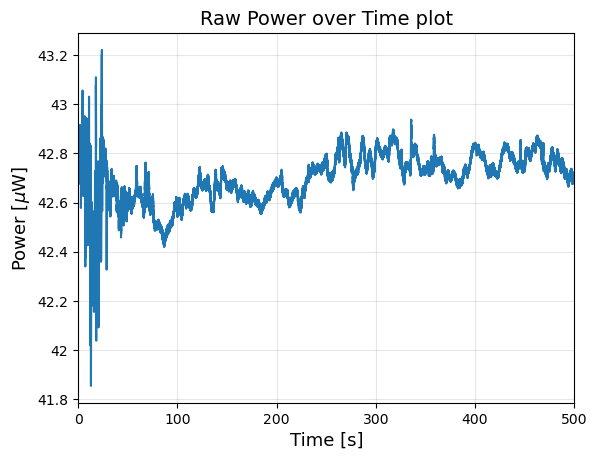

In [37]:
#Initial vs Signal
plt.rcParams.update({'font.size': 10})
plt.rc('axes', titlesize=14)
plt.rc('axes', labelsize=13) 
fig, ax = plt.subplots()
ax.plot(ts, ys)
#ax.plot(ts2, ys2)
#ax.plot(ts3, ys3)
ax.set_xlabel('Time [s]')
ax.set_ylabel('Power [$\mu$W]')
ax.set_xlim(0, 500)
#ax.set_ylim([0,np.max(ys)+(0.05*np.max(ys))])
#ax.set_ylim([0,np.max(ys)])
#ax.set_ylim([-0.001,0.007])
ax.grid(alpha=0.3)
ax.set_title('Raw Power over Time plot')
from matplotlib.ticker import StrMethodFormatter
from matplotlib.ticker import FuncFormatter

def times_1000(y, pos):
    return f"{y*1000000:g}"   # multiply label by 1000, strip redundant zeros

ax = plt.gca()             # or your existing Axes
ax.yaxis.set_major_formatter(FuncFormatter(times_1000))
plt.savefig('AppendixA2_Raw.pdf', dpi=300)

In [65]:
m=5000
N=len(ys)
fs=1/(ts[1]-ts[0])
meanys=running_mean(ys, m)
meants=running_mean_times(N, fs, m)

In [233]:
#Initial vs Signal
plt.rcParams.update({'font.size': 10})
plt.rc('axes', titlesize=14)
plt.rc('axes', labelsize=13) 
fig, ax = plt.subplots()
ax.plot(ts,ys, label='Raw')
ax.plot(meants, meanys, label='Rolling Average')
#ax.plot(ts2, ys2)
#ax.plot(ts3, ys3)
ax.set_xlabel('Time [s]')
ax.set_ylabel('$\overline{P_{j}}$ [$\mu$W]')
ax.set_xlim(0, 500)
#ax.set_ylim([0,np.max(ys)+(0.05*np.max(ys))])
#ax.set_ylim([0,np.max(ys)])
#ax.set_ylim([-0.001,0.007])
ax.grid(alpha=0.3)
ax.set_title('Power over Time plot, Rolling Average: $m=5000$')
from matplotlib.ticker import StrMethodFormatter
from matplotlib.ticker import FuncFormatter

def times_1000(y, pos):
    return f"{y*1000000:g}"   # multiply label by 1000, strip redundant zeros

ax = plt.gca()             # or your existing Axes
ax.yaxis.set_major_formatter(FuncFormatter(times_1000))
ax.legend(loc='lower right', fontsize="14")
plt.savefig('AppendixA2_Rolling.pdf', dpi=300)

In [79]:
adys=adjacent_diff_of_means(meanys, m)
adts=adjacent_diff_times(N, fs, m)

In [97]:
%matplotlib qt

In [248]:
#Initial vs Signal
plt.rcParams.update({'font.size': 10})
plt.rc('axes', titlesize=14)
plt.rc('axes', labelsize=13) 
fig, ax = plt.subplots()
#ax.plot(ts,ys, label='Raw')
#ax.plot(meants, meanys, label='Rolling Average')
ax.plot(adts, adys, label='adjacent')

#ax.plot(ts2, ys2)
#ax.plot(ts3, ys3)
ax.set_xlabel('Time [s]')
ax.set_ylabel('$d_{j}$ [$\mu$W]')
ax.set_xlim(0, 500)
#ax.set_ylim([0,np.max(ys)+(0.05*np.max(ys))])
ax.set_ylim([-0.00000035,0.00000035])
#ax.set_ylim([-0.001,0.007])
ax.grid(alpha=0.3)
ax.set_title('Adjacent Mean Difference over Time plot, $m=5000$')
from matplotlib.ticker import StrMethodFormatter
from matplotlib.ticker import FuncFormatter

def times_1000(y, pos):
    return f"{y*1000000:g}"   # multiply label by 1000, strip redundant zeros

ax = plt.gca()             # or your existing Axes
ax.yaxis.set_major_formatter(FuncFormatter(times_1000))
#ax.legend()
plt.savefig('AppendixA2_Adjacent.pdf', dpi=300)

In [132]:
oadev=oavar_from_d(adys)

In [134]:
oadev

(1.4369952024744154e-15, 3.790771956309711e-08)

In [136]:
taus=np.load('taus_26_06_25.npy')

In [141]:
print(taus*1000)

[1.00000e+00 2.00000e+00 3.00000e+00 4.00000e+00 5.00000e+00 6.00000e+00
 8.00000e+00 1.00000e+01 1.30000e+01 1.60000e+01 2.10000e+01 2.70000e+01
 3.40000e+01 4.30000e+01 5.50000e+01 6.90000e+01 8.80000e+01 1.11000e+02
 1.41000e+02 1.78000e+02 2.26000e+02 2.86000e+02 3.62000e+02 4.59000e+02
 5.81000e+02 7.36000e+02 9.31000e+02 1.17900e+03 1.49300e+03 1.88900e+03
 2.39200e+03 3.02800e+03 3.83300e+03 4.85200e+03 6.14300e+03 7.77600e+03
 9.84400e+03 1.24610e+04 1.57740e+04 1.99680e+04 2.52770e+04 3.19980e+04
 4.05050e+04 5.12740e+04 6.49060e+04 8.21630e+04 1.04008e+05 1.31661e+05
 1.66666e+05]


In [146]:
print(taus2[0])

0.9999999999763531


In [148]:
taus2=(taus*1000)+0.00000000003

In [138]:
print(taus)

[1.00000e-03 2.00000e-03 3.00000e-03 4.00000e-03 5.00000e-03 6.00000e-03
 8.00000e-03 1.00000e-02 1.30000e-02 1.60000e-02 2.10000e-02 2.70000e-02
 3.40000e-02 4.30000e-02 5.50000e-02 6.90000e-02 8.80000e-02 1.11000e-01
 1.41000e-01 1.78000e-01 2.26000e-01 2.86000e-01 3.62000e-01 4.59000e-01
 5.81000e-01 7.36000e-01 9.31000e-01 1.17900e+00 1.49300e+00 1.88900e+00
 2.39200e+00 3.02800e+00 3.83300e+00 4.85200e+00 6.14300e+00 7.77600e+00
 9.84400e+00 1.24610e+01 1.57740e+01 1.99680e+01 2.52770e+01 3.19980e+01
 4.05050e+01 5.12740e+01 6.49060e+01 8.21630e+01 1.04008e+02 1.31661e+02
 1.66666e+02]


In [178]:
print(fs)

999.0009990009988


In [150]:
taus, sigmas = oadev_multi_tau(y, fs, m_values=taus2)

In [186]:
data=np.load('FSM_Icomparison_26_06_25.npy')
taus_other=data[1][0]
sigmas_other=data[1][1]

In [244]:
#Initial vs Signal
plt.rcParams.update({'font.size': 10})
plt.rc('axes', titlesize=14)
plt.rc('axes', labelsize=13) 
fig, ax = plt.subplots()
#ax.plot(ts,ys, label='Raw')
#ax.plot(meants, meanys, label='Rolling Average')
#ax.loglog(taus, sigmas, label='$\sigma_{OADEV}$')
ax.loglog(taus_other, sigmas_other, label='$\sigma_{OADEV}$')
ax.loglog(5.005000000000001,3.790771956309711e-08, marker='.',markersize=12, label='$m=5000$')
ax.set_xlabel('Averaging Time τ [s]')
ax.set_ylabel('$\sigma_{OADEV}$ [W]')
#ax.set_xlim(0, 500)
#ax.set_ylim([0,np.max(ys)+(0.05*np.max(ys))])
#ax.set_ylim([-0.00000035,0.00000035])
#ax.set_ylim([-0.001,0.007])
ax.grid(alpha=0.3)
ax.set_title('Overlapping Allan Deviation plot')
xscale_min=(np.min(data[1][0]))
xscale_max=(np.max(data[1][0]))
ax.legend(loc='upper left', fontsize="14")
ax.set_xlim(xscale_min, xscale_max)
#ax[0].set_ylim([1*(10**(-12)),0.1])
ax = plt.gca()             # or your existing Axes
plt.savefig('AppendixA2_ODEV.pdf', dpi=300)

In [202]:
5000*(ts[1]-ts[0])

5.005000000000001